# AulaSense – Versión D: Separación de registro y consultas

**Proyecto:** AulaSense – Monitoreo Inteligente de Aulas  
**Actividad:** Análisis y mejora del diseño de software  
**Integrante:** Daniela Sánchez García

## 1. Descripción de la propuesta

En el diseño original de AulaSense, la clase `SistemaAulaSense`
concentra diferentes responsabilidades, como recibir mediciones,
guardar información, consultar registros y generar reportes.

Mi propuesta consiste en separar las operaciones de registro
de las operaciones de consulta, para que cada parte del sistema
tenga una responsabilidad más específica.

Esta organización permite modificar la forma de almacenar los
datos sin tener que cambiar las funciones que los consultan
o muestran al usuario.

## 2. Clases propuestas

| Clase | Responsabilidad |
|---|---|
| ServicioRegistro | Recibir, validar y almacenar las mediciones de los sensores. |
| ServicioConsultas | Recuperar las mediciones registradas y permitir búsquedas por aula. |
| GeneradorReporte | Organizar la información consultada y generar resúmenes. |
| Dashboard | Presentar los resultados de las consultas y los reportes. |

## 3. Objetivo de la mejora

Reducir la cantidad de responsabilidades concentradas en una
sola clase, facilitando el mantenimiento, las pruebas y la
incorporación de nuevas funcionalidades.

Esta propuesta se inspira en la separación de operaciones de
escritura y lectura, sin implementar una arquitectura CQRS
completa con bases de datos independientes.

## 4. Implementación de la propuesta en Python

Para demostrar el funcionamiento de la propuesta se utilizarán
mediciones simuladas de las aulas.

El sistema estará dividido en cuatro clases:

- ServicioRegistro: valida y almacena mediciones.
- ServicioConsultas: recupera información por aula.
- GeneradorReporte: calcula resúmenes de las mediciones.
- Dashboard: presenta los resultados.

Se utilizará una lista de Python como almacenamiento temporal,
sin necesidad de conectar una base de datos real.

In [1]:
# AulaSense - Versión D
# Separación de registro y consultas

class ServicioRegistro:
    def __init__(self, almacenamiento):
        self.almacenamiento = almacenamiento

    def registrar(self, aula, temperatura, humedad, ocupacion):
        if not aula or not isinstance(aula, str):
            raise ValueError("El nombre del aula no es válido")

        if not 0 <= humedad <= 100:
            raise ValueError("La humedad debe estar entre 0 y 100")

        if ocupacion < 0:
            raise ValueError("La ocupación no puede ser negativa")

        medicion = {
            "aula": aula,
            "temperatura": temperatura,
            "humedad": humedad,
            "ocupacion": ocupacion
        }

        self.almacenamiento.append(medicion)
        return medicion


class ServicioConsultas:
    def __init__(self, almacenamiento):
        self.almacenamiento = almacenamiento

    def consultar_por_aula(self, aula):
        return [
            medicion
            for medicion in self.almacenamiento
            if medicion["aula"] == aula
        ]

    def consultar_todas(self):
        return list(self.almacenamiento)


class GeneradorReporte:
    def generar_resumen(self, mediciones):
        if not mediciones:
            return {"mensaje": "No hay mediciones disponibles"}

        cantidad = len(mediciones)

        return {
            "total_mediciones": cantidad,
            "temperatura_promedio": round(
                sum(m["temperatura"] for m in mediciones) / cantidad, 2
            ),
            "humedad_promedio": round(
                sum(m["humedad"] for m in mediciones) / cantidad, 2
            ),
            "ocupacion_promedio": round(
                sum(m["ocupacion"] for m in mediciones) / cantidad, 2
            )
        }


class Dashboard:
    def mostrar(self, aula, reporte):
        print(f"\n===== AulaSense: {aula} =====")

        for indicador, valor in reporte.items():
            print(f"{indicador}: {valor}")

In [2]:
# Crear almacenamiento temporal
mediciones = []

# Crear los objetos de las cuatro clases
registro = ServicioRegistro(mediciones)
consultas = ServicioConsultas(mediciones)
reportes = GeneradorReporte()
dashboard = Dashboard()

# Simular mediciones de tres aulas
registro.registrar("Aula 101", 24.5, 55, 20)
registro.registrar("Aula 101", 26.0, 60, 25)
registro.registrar("Aula 102", 23.0, 50, 15)
registro.registrar("Aula 103", 27.5, 65, 30)

# Consultar las mediciones del Aula 101
datos_aula = consultas.consultar_por_aula("Aula 101")

# Generar un reporte
reporte = reportes.generar_resumen(datos_aula)

# Mostrar los resultados
dashboard.mostrar("Aula 101", reporte)


===== AulaSense: Aula 101 =====
total_mediciones: 2
temperatura_promedio: 25.25
humedad_promedio: 57.5
ocupacion_promedio: 22.5


## 5. Pruebas de funcionamiento

Se realizaron pruebas con datos simulados para comprobar
el funcionamiento de las clases propuestas.

Las pruebas permiten verificar el registro de mediciones,
las consultas por aula, la generación de reportes y
la validación de datos incorrectos.

In [3]:
# Pruebas de funcionamiento de AulaSense

# Prueba 1: Registro de mediciones
assert len(mediciones) == 4
print("Prueba 1: Registro de mediciones - CORRECTO")

# Prueba 2: Consulta por aula
datos = consultas.consultar_por_aula("Aula 101")
assert len(datos) == 2
print("Prueba 2: Consulta por aula - CORRECTO")

# Prueba 3: Generación de reportes
resumen = reportes.generar_resumen(datos)
assert resumen["temperatura_promedio"] == 25.25
print("Prueba 3: Generación de reportes - CORRECTO")

# Prueba 4: Validación de humedad incorrecta
try:
    registro.registrar("Aula 104", 25, 120, 20)
    print("Prueba 4: ERROR, se aceptó humedad incorrecta")
except ValueError:
    print("Prueba 4: Validación de humedad - CORRECTO")

# Prueba 5: Consulta de aula sin registros
datos_vacios = consultas.consultar_por_aula("Aula 999")
assert datos_vacios == []
print("Prueba 5: Aula sin registros - CORRECTO")

Prueba 1: Registro de mediciones - CORRECTO
Prueba 2: Consulta por aula - CORRECTO
Prueba 3: Generación de reportes - CORRECTO
Prueba 4: Validación de humedad - CORRECTO
Prueba 5: Aula sin registros - CORRECTO


## 6. Diagrama de clases de la propuesta mejorada

La propuesta divide las responsabilidades de la clase original
SistemaAulaSense en cuatro clases especializadas.

ServicioRegistro se encarga de registrar las mediciones.
ServicioConsultas permite recuperar los datos almacenados.
GeneradorReporte procesa las consultas y calcula indicadores.
Dashboard presenta los resultados al usuario.

ServicioRegistro y ServicioConsultas utilizan un almacenamiento
compartido. GeneradorReporte recibe los datos de las consultas
y Dashboard recibe los reportes generados.

Esta separación permite modificar una funcionalidad sin
tener que cambiar toda la estructura del sistema.

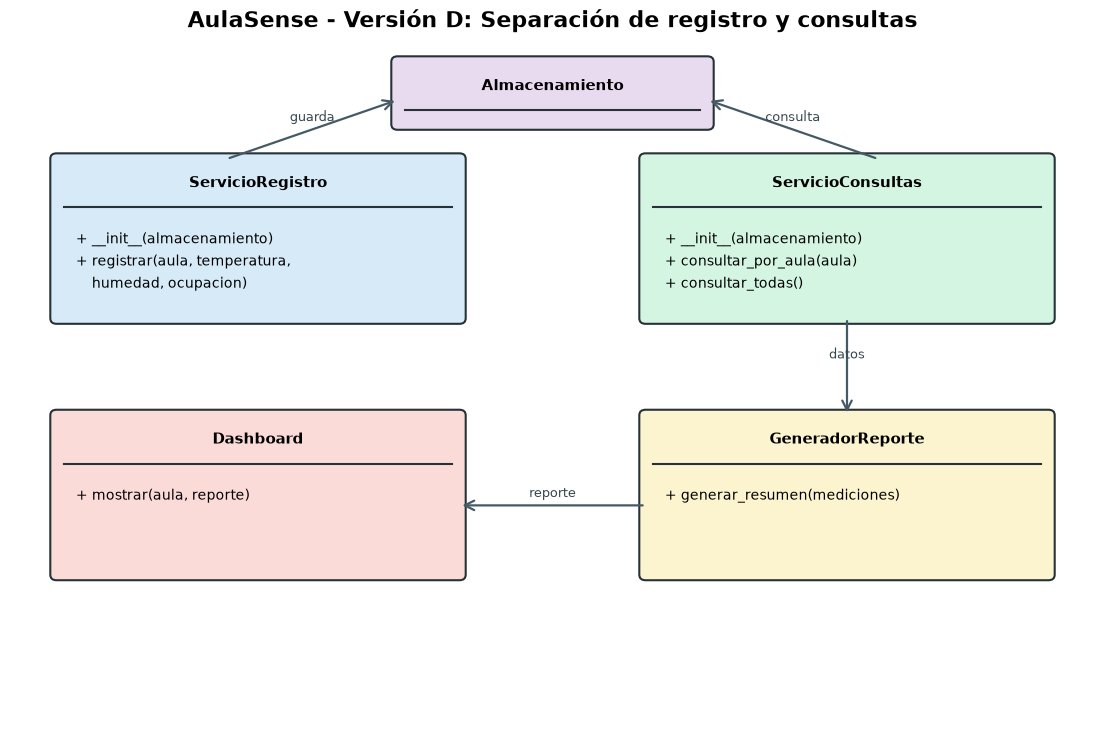

In [4]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(14, 9))
ax.set_xlim(0, 14)
ax.set_ylim(0, 10)
ax.axis("off")

def clase(x, y, ancho, alto, nombre, metodos, color):
    rect = FancyBboxPatch(
        (x, y), ancho, alto,
        boxstyle="round,pad=0.08",
        linewidth=1.5,
        edgecolor="#263238",
        facecolor=color
    )
    ax.add_patch(rect)

    ax.text(
        x + ancho / 2, y + alto - 0.35,
        nombre, ha="center", va="center",
        fontsize=11, fontweight="bold"
    )

    ax.plot(
        [x + 0.1, x + ancho - 0.1],
        [y + alto - 0.7, y + alto - 0.7],
        color="#263238"
    )

    ax.text(
        x + 0.25, y + alto - 1,
        metodos, ha="left", va="top",
        fontsize=10, linespacing=1.6
    )

def relacion(inicio, fin, etiqueta):
    flecha = FancyArrowPatch(
        inicio, fin,
        arrowstyle="->",
        mutation_scale=17,
        linewidth=1.6,
        color="#455A64"
    )
    ax.add_patch(flecha)

    mx = (inicio[0] + fin[0]) / 2
    my = (inicio[1] + fin[1]) / 2

    ax.text(
        mx, my + 0.12, etiqueta,
        ha="center", fontsize=9,
        color="#37474F"
    )

clase(
    0.6, 6.1, 5.2, 2.3,
    "ServicioRegistro",
    "+ __init__(almacenamiento)\n+ registrar(aula, temperatura,\n    humedad, ocupacion)",
    "#D6EAF8"
)

clase(
    8.2, 6.1, 5.2, 2.3,
    "ServicioConsultas",
    "+ __init__(almacenamiento)\n+ consultar_por_aula(aula)\n+ consultar_todas()",
    "#D5F5E3"
)

clase(
    8.2, 2.4, 5.2, 2.3,
    "GeneradorReporte",
    "+ generar_resumen(mediciones)",
    "#FCF3CF"
)

clase(
    0.6, 2.4, 5.2, 2.3,
    "Dashboard",
    "+ mostrar(aula, reporte)",
    "#FADBD8"
)

# Almacenamiento compartido por los dos servicios
clase(
    5.0, 8.9, 4.0, 0.9,
    "Almacenamiento",
    "",
    "#E8DAEF"
)

relacion((2.8, 8.4), (5.0, 9.25), "guarda")
relacion((11.2, 8.4), (9.0, 9.25), "consulta")
relacion((10.8, 6.1), (10.8, 4.7), "datos")
relacion((8.2, 3.4), (5.8, 3.4), "reporte")

ax.set_title(
    "AulaSense - Versión D: Separación de registro y consultas",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.show()

## 7. Justificación de la propuesta

### ¿Por qué elegí este diseño?

Elegí separar las operaciones de registro y consulta porque
en el diseño original una sola clase se encargaba de casi
todo el funcionamiento de AulaSense.

Con esta propuesta, cada clase tiene una tarea más específica.
Por ejemplo, ServicioRegistro se encarga de guardar las
mediciones, mientras que ServicioConsultas permite recuperar
la información sin modificarla.

GeneradorReporte utiliza los datos consultados para calcular
indicadores y Dashboard se encarga de mostrarlos.

### 7.1. Mantenimiento

Al tener las funciones separadas, es más sencillo localizar
y corregir errores. Si necesitamos modificar la manera de
generar reportes, podemos trabajar en GeneradorReporte sin
cambiar la lógica de registro.

### 7.2. Reutilización

Las clases pueden utilizarse en diferentes partes del sistema.
Por ejemplo, ServicioConsultas podría proporcionar información
tanto al dashboard como a una futura aplicación móvil.

### 7.3. Pruebas

La separación permite comprobar las funciones de manera
independiente. En el prototipo se realizaron cinco pruebas
para verificar el registro, las consultas, los reportes
y la validación de datos.

### 7.4. Extensibilidad

Si en el futuro AulaSense necesita nuevos reportes o formas
de visualizar la información, será más sencillo incorporarlos
sin modificar todas las clases.

### 7.5. Limitaciones

Esta versión utiliza una lista de Python para almacenar las
mediciones, por lo que los datos no permanecen guardados al
cerrar el programa.

Además, los servicios de registro y consulta todavía
comparten el mismo almacenamiento. En una implementación
real sería conveniente utilizar un repositorio de datos
y una base de datos persistente.

## 8. Comparación del diseño original y la propuesta mejorada

| Aspecto | Diseño original | Propuesta mejorada |
|---|---|---|
| Organización | Una clase central concentra muchas funciones. | Las responsabilidades se distribuyen en cuatro clases. |
| Registro de datos | SistemaAulaSense recibe y guarda las mediciones. | ServicioRegistro se encarga del registro. |
| Consultas | La clase central recupera los datos. | ServicioConsultas realiza las consultas. |
| Reportes | La misma clase genera reportes. | GeneradorReporte calcula los indicadores. |
| Visualización | SistemaAulaSense también controla la presentación. | Dashboard muestra los resultados. |
| Mantenimiento | Los cambios pueden afectar diferentes funciones. | Las modificaciones quedan más localizadas. |
| Pruebas | Es más difícil aislar responsabilidades. | Las funciones pueden comprobarse por separado. |
| Crecimiento | La clase central puede seguir aumentando de tamaño. | Es más sencillo agregar componentes especializados. |

## 9. Conclusión individual

La propuesta de separación de registro y consultas permite
organizar mejor las responsabilidades de AulaSense.

En lugar de concentrar todas las operaciones en una sola
clase, se utilizan componentes especializados para registrar
mediciones, consultar información, generar reportes y
mostrar resultados.

El ejemplo desarrollado en Python permitió comprobar
el funcionamiento de esta organización mediante datos
simulados y cinco pruebas.

Considero que esta propuesta facilita el mantenimiento,
las pruebas y la incorporación de nuevas funcionalidades,
aunque todavía sería necesario integrar una base de datos
real para utilizarla en un sistema completo.